<a href="https://colab.research.google.com/github/BorisK7/my_bot/blob/main/homeworks/hw1/homework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание блока 1. Лекции 1–2

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/homeworks/hw1/homework.ipynb)

Домашние задания выдаются **раз в две недели** и охватывают обе лекции блока. Это задание — по лекциям 1 и 2: Cross-Entropy и оценка политики по Монте-Карло, своя среда в Gymnasium, уравнения Беллмана и оптимальная политика.

**Почти всё здесь вы уже писали на семинарах.** Задание переносит те же функции на новые среды: часть 1 — семинар 1 на озере 8×8, части 2 и 3 — семинар 2 со своим лабиринта на склад. Берите код из своих решений семинаров, это и задумано.

Всего **100 баллов**:

| Часть | Баллы | Откуда брать |
|---|---|---|
| 1. Cross-Entropy и оценка политик на озере 8×8 | 35 | семинар 1, разделы 3–5 |
| 2. Своя среда: управление запасами | 25 | семинар 2, раздел 7 |
| 3. Уравнения Беллмана на складе | 30 | семинар 2, разделы 3–5 |
| 4. Теория | 10 | лекция 2, разделы 3–4 |

Части с `assert` проверяются автоматически при запуске ячейки: если assert не упал, часть засчитана. Графики и письменные ответы проверяются вручную — пишите их прямо в markdown-ячейках вместо слова `TODO`.

Весь ноутбук держится на одном наборе функций: `run_session`, `discounted_return`, `evaluate` и `cross_entropy_method`. Вы пишете их в части 1 и дальше переиспользуете на складе, поэтому не переопределяйте их по ходу ноутбука. Политика везде — таблица «состояние × действие» с вероятностями.

**Не забудьте про квизы.** К этому блоку их два — по лекции 1 и по лекции 2. Пройдите оба в зачётном режиме и положите коды результатов в `quiz/week01.txt` и `quiz/week02.txt`.

Первые две ячейки служебные: установка пакетов в Colab и подключение модуля с картинками. Запустите и идите дальше.

In [2]:
# Если ноутбук открыт в Google Colab: ставим недостающие пакеты. Локально (после uv sync) ячейка ничего не делает.
import importlib.util, subprocess, sys
if importlib.util.find_spec("gymnasium") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[toy-text,classic-control]"], check=True)

In [3]:
# Служебное: рисовальщики лежат в lake_plots.py из папки семинара 1 — читать не нужно,
# список функций с сигнатурами есть в его docstring. В Colab скачиваем модуль.
import pathlib, sys, urllib.request

HERE = next((p for p in ["", "../../01-intro/seminar", "01-intro/seminar"]
             if (pathlib.Path(p) / "lake_plots.py").exists()), None)
if HERE is None:
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main/01-intro/seminar/lake_plots.py",
        "lake_plots.py")
    HERE = ""
sys.path.insert(0, str(pathlib.Path(HERE).resolve()))

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from lake_plots import ARROWS, draw_lake, draw_policy, lake_desc, plot_values

Дальше — функции из лекции и семинара недели 1: `discounted_return`, `run_session` и оценка доли успехов. В частях 1–2 работаем с озером 8×8.

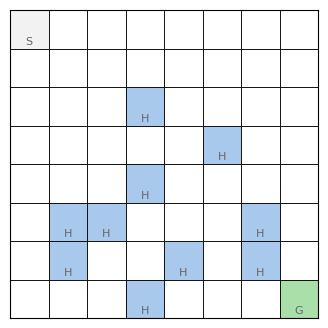

SFFFFFFF
FFFFFFFF
FFFHFFFF
FFFFFHFF
FFFHFFFF
FHHFFFHF
FHFFHFHF
FFFHFFFG


In [4]:
GAMMA = 0.95

def discounted_return(rewards, gamma=GAMMA):
    """G = r_0 + γ r_1 + γ² r_2 + ..."""
    return sum(gamma ** t * r for t, r in enumerate(rewards))

def run_session(env, policy, rng, max_steps=100):
    """Один эпизод политикой-таблицей policy. Возвращает состояния (включая последнее), действия и награды."""
    s, _ = env.reset(seed=int(rng.integers(1_000_000)))
    states, actions, rewards = [s], [], []
    for _ in range(max_steps):
        a = int(rng.choice(len(policy[s]), p=policy[s]))      # действие ~ π(· | s)
        s, r, terminated, truncated, _ = env.step(a)
        states.append(s); actions.append(a); rewards.append(r)
        if terminated or truncated:
            break
    return states, actions, rewards


def success_rate(env, policy, n_episodes=500, seed=0):
    """Доля эпизодов, дошедших до цели."""
    rng = np.random.default_rng(seed)
    return np.mean([sum(run_session(env, policy, rng)[2]) > 0 for _ in range(n_episodes)])

env8 = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=False)
desc8 = lake_desc(env8)
n_states, n_actions = env8.observation_space.n, env8.action_space.n
draw_lake(desc8, size=4); plt.show()
print("\n".join(desc8))

## Часть 1. Cross-Entropy и оценка политик на озере 8×8 (35 баллов)

*Это семинар 1 целиком, перенесённый на поле побольше: 64 состояния, до цели далеко, случайная политика доходит реже, чем в одном эпизоде из пятисот.*

### 1.1 Обучение Cross-Entropy (20 баллов)

Перенесите из своего решения семинара 1 `select_elite`, `update_policy` и `cross_entropy_method`. Одно отличие от семинара: у цикла появились параметры `gamma` и `max_steps`, и их нужно передавать дальше — в `discounted_return` и `run_session` соответственно. На складе из части 2 это понадобится.

Гиперпараметры подбирать не нужно — рабочий набор дан в следующей ячейке. На 8×8 главное это `n_sessions`: успешных эпизодов у случайной политики единицы на сотни, и если играть мало эпизодов за итерацию, в элиту не попадёт ни одного успешного и обучение застынет на нуле.

Самопроверка требует долю успехов **не меньше 90 %** у выученной стохастической политики.

In [20]:

def select_elite(sessions, scores, q=0.7):
    elite=[]
    #sessions = states, actions, rewards
    min_score=min(scores)
    threshold = np.quantile(scores, q)
    for _ in range(0,len(scores)):
      if (scores[_] > min(scores)) & (_ >= threshold):
        elite.append(sessions[_])
    return(elite)

def update_policy(policy, elite, laplace=0.0, mix=1.0):
    counts = np.zeros((n_states, n_actions))
    for states, actions, rewards in elite:
          for s, a in zip(states, actions):
            counts[s, a] += 1


    seen = counts.sum(axis=1) > 0
    smoothed = counts[seen] + laplace
    new_policy = policy.copy()
    new_policy[seen] = smoothed / smoothed.sum(axis=1, keepdims=True)

    return mix * new_policy + (1 - mix) * policy

def cross_entropy_method(env, n_iter=15, n_sessions=200, q=0.7, laplace=0.0, mix=1.0,
                         seed=0, gamma=GAMMA, max_steps=100):
    rng = np.random.default_rng(seed)
    policy = np.ones((env.observation_space.n, env.action_space.n)) / env.action_space.n
    log = {"policies": [], "success": [], "return": []}
    for _ in range(n_iter):
        sessions = [run_session(env, policy, rng, max_steps) for _ in range(n_sessions)]     # 1. сыграть
        returns = [discounted_return(r, gamma) for *_, r in sessions]
        elite = select_elite(sessions, returns, q)                                # 2. отобрать элиту
        log["policies"].append(policy); log["return"].append(np.mean(returns))
        log["success"].append(np.mean([G > 0 for G in returns]))
        policy = update_policy(policy, elite, laplace, mix)                       # 3. подстроить политику
    return policy, log

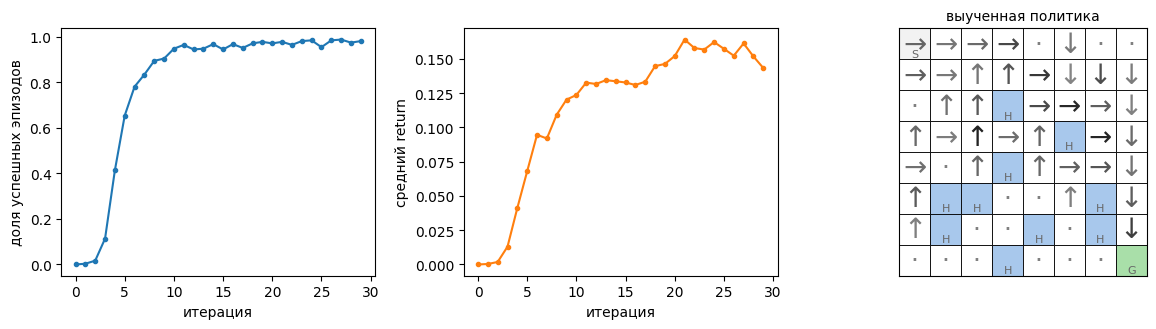

доля успехов: 97.0%


In [21]:
# Рабочий набор гиперпараметров — менять не обязательно.
policy8, log8 = cross_entropy_method(env8, n_iter=30, n_sessions=300, q=0.7,
                                     laplace=0.5, mix=0.5, seed=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(log8["success"], marker="."); axes[0].set_xlabel("итерация"); axes[0].set_ylabel("доля успешных эпизодов")
axes[1].plot(log8["return"], marker=".", color="C1"); axes[1].set_xlabel("итерация"); axes[1].set_ylabel("средний return")
draw_policy(policy8, desc8, ax=axes[2], title="выученная политика"); plt.tight_layout(); plt.show()

rate8 = success_rate(env8, policy8, n_episodes=1000)
print(f"доля успехов: {rate8:.1%}")
assert policy8.shape == (64, 4) and np.allclose(policy8.sum(axis=1), 1)
assert rate8 >= 0.9, "политика должна доходить до цели не реже, чем в 90% эпизодов"

### 1.2 Жадная политика и нулевые вероятности (5 баллов)

Постройте жадную версию `policy8` (единица на `argmax` в каждой клетке, как в задаче 5.1 семинара 1) и сравните долю успехов жадной и стохастической политик. Ответьте письменно:

1. Дошла ли жадная версия до цели? В каком случае жадная версия **не** доходит, хотя стохастическая доходит почти всегда? Подсказка: посмотрите на клетки с точкой — туда элита не заходила, и `argmax` там выбирает действие 0, то есть «влево».
2. Почему нулевая вероятность действия опаснее, чем просто маленькая? Свяжите ответ с исследованием и использованием из лекции 1.

In [23]:
greedy8 = np.zeros_like(policy8)
greedy8[np.arange(len(policy8)), policy8.argmax(axis=1)] = 1.0
print(f"стохастическая: {success_rate(env8, policy8, 1000):.1%}, жадная: {success_rate(env8, greedy8, 1000):.1%}")

стохастическая: 97.0%, жадная: 100.0%


_Ваш ответ:_
1. Дошла до цели. Если несколько успешных путей проходит через соседние клетки, так что получится петля. И вероятностная модель выходит из нее, а жадная политика нет так как детерминирована. Туда куда стохастическая не заходила - аргмакс тоже не попадет, по крайней мере не в этой среде.
2. При нулевой вероятности мы лишаемся исследования "не узнаем, что в кафе напротив вкуснее"

### 1.3 Три политики по Монте-Карло (10 баллов)

*Это задача 3.1 семинара 1 на новой карте.*

Напишите `evaluate(env, policy, n_episodes, seed, gamma, max_steps)` — она возвращает пару **(средний return, стандартная ошибка)**. Это единственная функция оценки на весь ноутбук: в частях 2 и 3 ею же оцениваются политики склада.

Два предостережения — оба про ошибки, которые потом трудно найти:

* `rng = np.random.default_rng(seed)` создайте **один раз** в начале функции. Если создавать его внутри цикла, все эпизоды выйдут одинаковыми, а ошибка — нулевой;
* `max_steps` обязательно передавайте в `run_session`. У `evaluate` значение по умолчанию 1000, у `run_session` — 100, и если забыть, эпизоды молча обрежутся на сотом шаге. На озере это незаметно, а на складе с горизонтом 150 дней ответ уедет, и искать причину вы будете не там.

Оцените три политики на `env8`: равномерную, **маршрут, написанный руками** (словарь «клетка → действие», как на семинаре; подсказка: вдоль верхнего края, потом вдоль правого) и выученную в 1.1. Нарисуйте столбчатую диаграмму с усами ошибки.

Ответьте текстом: сколько эпизодов нужно, чтобы стандартная ошибка оценки равномерной политики стала меньше 0.001?

In [32]:
LEFT, DOWN, RIGHT, UP = 0, 1, 2, 3

def table_policy(route, n_states=64, n_actions=4, default=LEFT):
    policy = np.zeros((n_states, n_actions))
    for s in range(n_states):
        policy[s, route.get(s, default)] = 1.0
    return policy

def evaluate(env, policy, n_episodes=1000, seed=0, gamma=GAMMA, max_steps=1000):
    rng = np.random.default_rng(seed)
    returns = []
    for _ in range(n_episodes):
        states, actions, rewards = run_session(env, policy, rng, max_steps)
        returns.append(discounted_return(rewards, gamma))
    returns = np.array(returns)
    return returns.mean(), returns.std() / np.sqrt(n_episodes)


route8 = {s: RIGHT for s in range(0, 7)}
route8.update({s: DOWN for s in range(7, 63, 8)})
route_policy8 = table_policy(route8)

uniform8 = np.ones((64, 4)) / 4

mean_p, se_p = evaluate(env8, policy8)
mean_u, se_u = evaluate(env8, uniform8, n_episodes=10000)
mean_r, se_r = evaluate(env8, route_policy8)
for name, m, se in [("выученная", mean_p, se_p), ("маршрут", mean_r, se_r), ("равномерная", mean_u, se_u)]:
    print(f"{name:12s} {m:.4f} ± {se:.8f}")

выученная    0.1525 ± 0.00320742
маршрут      0.5133 ± 0.00000000
равномерная  0.0001 ± 0.00004350


_Ваш ответ:_
n > (σ/0.001)² se = σ / √n => σ = √n*se ~ 0.0044 => n ~ 4.4^2 ~ 20 эпизодов

## Часть 2. Своя среда: управление запасами (25 баллов)

До сих пор среду давали готовой. Теперь напишем свою — и убедимся, что функциям из частей 1 и 2 всё равно, чья это среда.

**Задача.** Вы управляете складом одного товара. Каждый день:

1. утром на складе `stock` единиц (от 0 до `capacity`);
2. вы решаете, сколько **заказать**: действие $a \in \{0, 1, \ldots, \text{max\_order}\}$; заказ приезжает сразу, но склад не вмещает больше `capacity` — лишнее пропадает;
3. днём приходит **случайный спрос** $d$ (Пуассон со средним `demand_mean`), продаётся $\min(d, \text{stock})$ единиц;
4. вечером остаток переходит на завтра. Эпизод длится `horizon` дней.

Экономика дня: выручка `price` за проданную единицу, `order_cost` за **каждую заказанную** (даже если она не поместилась), `holding_cost` за каждую единицу, оставшуюся к вечеру, и `stockout_cost` за каждую единицу неудовлетворённого спроса.

Это классическая задача исследования операций, и RL здесь не единственный способ, зато прекрасный полигон: дискретное состояние, дискретное действие, честная случайность — и, главное для лекции 2, распределение спроса известно. Значит, в части 3 модель $P$ и $R$ можно выписать **точно** и решить уравнения Беллмана, как на лекции и семинаре 2.

### 2.1 Класс среды (15 баллов)

*На семинаре 2 (раздел 7) вы разобрали `MazeEnv` и написали его `step`. Здесь — то же для склада, по тому же образцу: `__init__` и `reset` даны, ваше — `step`.*

Экономику дня считает готовая функция `day_reward` — выписывать формулу награды самому не нужно, её легко испортить, а ошибка всплывёт только в части 3. Ваше дело — собрать из неё шаг среды.

Реализуйте `step`:

* разыграйте спрос через `self.np_random.poisson(self.demand_mean)` — тогда среда воспроизводима по сиду;
* посчитайте награду и новый остаток через `day_reward`;
* увеличьте счётчик дней и определите, кончился ли эпизод;
* в `info` положите `demand` и `sold`.

Подумайте, какой из флагов, `terminated` или `truncated`, правильно выставлять в конце горизонта, и объясните выбор в комментарии. Подсказка: после `horizon` дней задача **закончена по условию**, а не оборвана снаружи.

In [ ]:
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env


def day_reward(env, stock, order, demand):
    """Экономика одного дня. Возвращает (награда, остаток к вечеру, сколько продали).

    Дана готовой: это та же формула, по которой в части 3 строится модель R[s, a].
    """
    on_hand = min(stock + order, env.capacity)        # заказ приехал, лишнее за вместимость пропало
    sold = min(demand, on_hand)
    left = on_hand - sold                             # остаток к вечеру
    reward = (env.price * sold                        # выручка
              - env.order_cost * order                # платим за каждую заказанную, даже непоместившуюся
              - env.holding_cost * left               # хранение остатка
              - env.stockout_cost * (demand - sold))  # штраф за неудовлетворённый спрос
    return reward, left, sold

In [ ]:
class InventoryEnv(gym.Env):
    metadata = {"render_modes": ["ansi"]}

    def __init__(self, capacity=20, max_order=10, demand_mean=4.0, horizon=30, initial_stock=10,
                 price=5.0, order_cost=2.0, holding_cost=0.5, stockout_cost=3.0, render_mode=None):
        self.capacity, self.max_order = capacity, max_order
        self.demand_mean, self.horizon, self.initial_stock = demand_mean, horizon, initial_stock
        self.price, self.order_cost = price, order_cost
        self.holding_cost, self.stockout_cost = holding_cost, stockout_cost
        self.render_mode = render_mode

        self.observation_space = spaces.Discrete(capacity + 1)   # наблюдение — текущий остаток
        self.action_space = spaces.Discrete(max_order + 1)       # действие — сколько заказать

        self.stock = initial_stock
        self.day = 0

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                                 # заводит self.np_random
        self.stock, self.day = self.initial_stock, 0
        return self.stock, {}

    def step(self, action):
        # TODO 2.1: спрос через self.np_random, награда и новый остаток через day_reward,
        #           день +1, конец горизонта; вернуть (obs, reward, terminated, truncated, info)
        raise NotImplementedError

    def render(self):
        if self.render_mode == "ansi":
            return f"день {self.day:2d}: на складе {self.stock:2d}"

In [ ]:
# Самопроверка 2.1
env = InventoryEnv()
check_env(env)

obs, info = env.reset(seed=0)
assert obs == 10 and env.observation_space.contains(obs)
assert env.action_space.n == 11 and env.observation_space.n == 21

# заказ выше вместимости обрезается: 10 + 10 = 20, больше capacity не бывает
env.reset(seed=0)
obs, r, term, trunc, info = env.step(10)
assert 0 <= obs <= 20 and "demand" in info and "sold" in info
assert info["sold"] <= 20 and obs == 20 - info["sold"], "продано не может быть больше остатка после заказа"

# эпизод длится ровно horizon дней
env.reset(seed=1)
for day in range(30):
    obs, r, term, trunc, info = env.step(0)
    assert term == (day == 29), "terminated должен стать True ровно после horizon-го дня"

# воспроизводимость: одинаковый seed -> одинаковый спрос
def demands(seed):
    e = InventoryEnv(); e.reset(seed=seed)
    return [e.step(3)[4]["demand"] for _ in range(10)]
assert demands(42) == demands(42) and demands(42) != demands(43)
# награда и новый остаток должны считаться через day_reward — иначе модель из части 3 не сойдётся
env.reset(seed=7)
obs, r, term, trunc, info = env.step(4)
_expected, _left, _sold = day_reward(env, 10, 4, info["demand"])
assert np.isclose(r, _expected) and obs == _left and info["sold"] == _sold, \
    "награду и остаток считайте через day_reward(env, stock, order, demand)"
print("OK: InventoryEnv проходит проверки")

### 2.2 Политика «пополнять до уровня» (10 баллов)

*На семинаре 2 (раздел 8) вы меняли параметр лабиринта и смотрели, как меняется оптимальная стратегия. Здесь — перебор параметра ручной политики.*

Политика здесь — такая же таблица, как на озере: строка на каждый остаток, столбец на каждое количество заказа. Перевод правила «остаток → заказ» в такую таблицу делает готовая `rule_to_table` — после неё работают и `run_session`, и `evaluate` из части 1.

Классическая политика склада — **пополнять до уровня** $S$: заказать $\max(0, S - \text{stock})$, но не больше `max_order` (base-stock policy). Для каждого $S$ от 0 до 20 оцените **прибыль за 30 дней**, все дни равноценны: `evaluate(InventoryEnv(), table, n_episodes=200, gamma=1.0, max_steps=31)`. Постройте график «прибыль в зависимости от $S$». Для сравнения напечатайте прибыль политики «ничего не заказывать».

Лучшую политику сохраните таблицей `pi_base` — она понадобится в части 3. Ответьте текстом: почему прибыль сначала растёт с $S$, а потом падает?

In [ ]:
def rule_to_table(rule, n_states=21, n_actions=11):
    """Правило «остаток -> сколько заказать» превращаем в таблицу-политику. Дана готовой."""
    table = np.zeros((n_states, n_actions))
    for s in range(n_states):
        table[s, min(max(int(rule(s)), 0), n_actions - 1)] = 1.0   # заказ обрезаем по max_order
    return table

# TODO 2.2: для каждого S от 0 до 20 оценить прибыль за 30 дней через
#           evaluate(InventoryEnv(), rule_to_table(...), n_episodes=200, gamma=1.0, max_steps=31),
#           построить график «прибыль от S» и напечатать прибыль политики «ничего не заказывать»
pi_base = ...   # TODO: таблица лучшей base-stock политики

In [ ]:
# Самопроверка 2.2
_t = rule_to_table(lambda s: min(10, 20 - s))
assert _t.shape == (21, 11) and np.allclose(_t.sum(axis=1), 1) and _t[15, 5] == 1, "rule_to_table: единица в столбце rule(s)"
_m, _se = evaluate(InventoryEnv(), rule_to_table(lambda s: 0), n_episodes=20, gamma=1.0, max_steps=31)
assert np.isscalar(_m) and np.isscalar(_se) and _se >= 0, "evaluate должна вернуть пару чисел: среднее и стандартную ошибку"
assert pi_base.shape == (21, 11) and np.allclose(pi_base.sum(axis=1), 1), "pi_base — таблица 21 × 11, строки суммируются в единицу"
print(f"OK: прибыль политики «ничего не заказывать» = {_m:.1f} ± {_se:.1f}")

_Ваш ответ:_ TODO

## Часть 3. Уравнения Беллмана на складе (30 баллов)

*Это вторая половина семинара 2: те же `evaluate_policy_exact` и `value_iteration`, только вместо лабиринта — склад.*

Спрос — Пуассон с известным средним, значит, модель переходов можно выписать явно. Она дана готовой: `inventory_mdp(env)` возвращает `P[s, a, s']` и `R[s, a]` ровно в том формате, что на лекции и семинаре. Как она устроена:

* после заказа на складе $m = \min(s + a, \text{capacity})$ единиц;
* при спросе $d$ продаётся $\min(d, m)$, остаток $s' = m - \min(d, m)$; все значения спроса $d \ge m$ приводят в $s' = 0$;
* $R[s, a]$ — **ожидаемая** награда дня: среднее по спросу от $\text{price}\cdot\min(d, m) - \text{order\_cost}\cdot a - \text{holding\_cost}\cdot s' - \text{stockout\_cost}\cdot\max(d - m, 0)$;
* горизонт в этой части считаем бесконечным, а задачу — дисконтированной с $\gamma = 0.95$ (`GAMMA` уже определена): тогда ценность не зависит от дня, и уравнения из лекции применимы дословно. Для конечного горизонта ценность зависела бы ещё и от номера дня; это тема недели 3.

Обратите внимание: $R[s, a]$ считается той же `day_reward`, что и шаг вашей среды, — модель и среда описывают одну и ту же экономику. Самопроверка это и подтверждает.

In [ ]:
def poisson_pmf(mean, d_max=60):
    """Вероятности спроса d = 0..d_max для Пуассона; хвост d > d_max добавлен к последней точке."""
    pmf = np.zeros(d_max + 1)
    pmf[0] = np.exp(-mean)
    for d in range(1, d_max + 1):
        pmf[d] = pmf[d - 1] * mean / d
    pmf[-1] += 1 - pmf.sum()
    return pmf

def inventory_mdp(env, d_max=60):
    """P[s, a, s'] и R[s, a] для InventoryEnv при бесконечном горизонте."""
    n_s, n_a = env.capacity + 1, env.max_order + 1
    P, R = np.zeros((n_s, n_a, n_s)), np.zeros((n_s, n_a))
    pmf = poisson_pmf(env.demand_mean, d_max)
    for s in range(n_s):
        for a in range(n_a):
            for d, pd in enumerate(pmf):
                reward, s_next, _ = day_reward(env, s, a, d)   # та же формула, что в вашем step
                P[s, a, s_next] += pd
                R[s, a] += pd * reward
    return P, R

P, R = inventory_mdp(InventoryEnv())

# Самопроверка модели: ожидаемая награда при s=10, a=0 сходится с Монте-Карло по вашей среде
assert P.shape == (21, 11, 21) and np.allclose(P.sum(axis=2), 1.0)
_e = InventoryEnv(); _rs = []
for _seed in range(3000):
    _e.reset(seed=_seed); _rs.append(_e.step(0)[1])
assert abs(np.mean(_rs) - R[10, 0]) < 0.3, f"R[10, 0] = {R[10, 0]:.2f}, а ваша среда даёт {np.mean(_rs):.2f}: проверьте награду в step"
print(f"OK: модель склада, R[10, 0] = {R[10, 0]:.2f}, Монте-Карло по среде {np.mean(_rs):.2f}")

### 3.1 Ценность ручной политики: точно и по Монте-Карло (12 баллов)

Перенесите с семинара `evaluate_policy_exact(policy, P, R, gamma)` — решение линейной системы $(I - \gamma P_\pi) V^\pi = r_\pi$ — и посчитайте $V^\pi$ для `pi_base`.

Затем проверьте ответ **по Монте-Карло**: для стартовых остатков 0, 10 и 20 вызовите `evaluate(InventoryEnv(initial_stock=s, horizon=150), pi_base, n_episodes=300, gamma=GAMMA, max_steps=150)`. Длинный горизонт имитирует бесконечный: $0.95^{150} \approx 5 \cdot 10^{-4}$.

Постройте график «остаток → $V^\pi$» и нанесите на него три точки Монте-Карло с усами в две стандартные ошибки. Объясните, почему кривая и точки должны совпасть и откуда берутся расхождения.

In [ ]:
def evaluate_policy_exact(policy, P, R, gamma=GAMMA):
    # TODO: как на семинаре
    raise NotImplementedError

V_base = evaluate_policy_exact(pi_base, P, R)
# TODO: Монте-Карло для остатков 0, 10, 20 и график

In [ ]:
# Самопроверка 3.1
assert V_base.shape == (21,)
_uniform = np.ones((21, 11)) / 11
_V = evaluate_policy_exact(_uniform, P, R)
_r = (_uniform * R).sum(axis=1)
assert np.allclose(_V, _r + GAMMA * np.einsum("sa,sat->st", _uniform, P) @ _V), "V^π должна удовлетворять уравнению Беллмана"
assert np.all(np.diff(V_base) > -1e-9), "ценность не убывает с ростом остатка: товар на складе не бывает вреден при разумной политике"
print(f"OK: V^π(остаток 10) = {V_base[10]:.1f}")

_Ваш ответ:_ TODO

### 3.2 Оптимальная политика заказов (18 баллов)

Перенесите с семинара `bellman_update` и `value_iteration(P, R, gamma, tol, max_iter)` → `(Q*, число итераций)`. Найдите $Q^*$, $V^* = \max_a Q^*$ и оптимальную политику $\pi^*(s) = \arg\max_a Q^*(s, a)$ в виде таблицы `pi_star`. Нарисуйте графики «остаток → заказ» для `pi_star` и `pi_base` на одной картинке и сравните $V^*(10)$ с $V^\pi(10)$ из 3.1.

Ответьте текстом:

* похожа ли $\pi^*$ на «пополнять до уровня $S$» и совпала ли она с лучшей ручной политикой? Если да, это не случайность: для такой модели склада оптимальность политики вида base-stock — классический результат теории запасов, и уравнение оптимальности его переоткрыло. Объясните своими словами, почему заказывать до фиксированного уровня разумно;
* сколько итераций понадобилось value iteration и сколько эпизодов взаимодействия со средой? Чем это отличается от Cross-Entropy?

In [ ]:
def bellman_update(Q, P, R, gamma=GAMMA):
    # TODO: как на семинаре
    raise NotImplementedError

def value_iteration(P, R, gamma=GAMMA, tol=1e-10, max_iter=1000):
    # TODO: как на семинаре; вернуть Q* и число итераций
    raise NotImplementedError

Q_star, n_iter = value_iteration(P, R)
V_star = Q_star.max(axis=1)
pi_star = ...   # TODO: таблица 21 × 11 с единицей на argmax Q*
# TODO 3.2: график «остаток → заказ» для pi_star и pi_base, сравнение V*(10) и V^π(10)

In [ ]:
# Самопроверка 3.2
assert Q_star.shape == (21, 11) and pi_star.shape == (21, 11)
assert np.allclose(Q_star, bellman_update(Q_star, P, R), atol=1e-6), "Q* должна удовлетворять уравнению оптимальности"
assert np.all(V_star >= V_base - 1e-6), "V* не меньше ценности ручной политики во всех состояниях"
assert np.allclose(evaluate_policy_exact(pi_star, P, R), V_star, atol=1e-4), "жадная по Q* политика имеет ценность V*"
print(f"OK: V*(10) = {V_star[10]:.1f}, у ручной политики V^π(10) = {V_base[10]:.1f}")

_Ваш ответ:_ TODO

## Часть 4. Теория (10 баллов)

Отвечайте прямо в markdown-ячейке ниже, используя LaTeX ($...$ или $$...$$). Показывайте промежуточные шаги, а не только финальный ответ.

**Уравнение Беллмана и связь $V$ с $Q$.**

1. Исходя из определения $V^\pi(s) = \mathbb E_\pi[G_t \mid S_t = s]$ и тождества $G_t = R_t + \gamma G_{t+1}$, выведите уравнение Беллмана для $V^\pi$. Явно укажите, где используется марковское свойство и где — то, что политика не зависит от времени.
2. Докажите две связи из лекции: $V^\pi(s) = \sum_a \pi(a \mid s)\, Q^\pi(s, a)$ и $Q^\pi(s, a) = r(s, a) + \gamma \sum_{s'} P(s' \mid s, a)\, V^\pi(s')$.
3. Выведите из них, что $V^*(s) = \max_a Q^*(s, a)$, и объясните, почему максимум появляется именно в первой связи, а не во второй.

_Ваш ответ:_ TODO

## Чек-лист перед сдачей

- [ ] 1.1: `cross_entropy_method` (с `gamma` и `max_steps`) проходит самопроверку на 8×8, есть кривые и картинка политики
- [ ] 1.2: жадная политика построена, есть ответы на два вопроса
- [ ] 1.3: три политики оценены со стандартными ошибками, есть диаграмма и ответ про число эпизодов
- [ ] 2.1: `InventoryEnv.step` написан, среда проходит `check_env` и самопроверку
- [ ] 2.2: есть график прибыли по уровню $S$, таблица `pi_base` и ответ
- [ ] 3.1: `evaluate_policy_exact` проходит самопроверку, есть график с точками Монте-Карло и ответ
- [ ] 3.2: `value_iteration` проходит самопроверку, есть график $\pi^*$ рядом с `pi_base` и ответы
- [ ] 4: вывод уравнения Беллмана и связей $V$–$Q$
- [ ] Коды квизов по лекциям 1 и 2 лежат в `quiz/week01.txt` и `quiz/week02.txt`
- [ ] Ноутбук выполнен целиком: «Restart & Run All» перед сдачей